# Speed Profiles

Each agent has a maximum speed (its speed profile), drawn by the line generator from `speed_ratio_map`, see [Scenario Generation](../scenario_generation).
Speeds are fractions of a cell per step: an agent with max speed `1/4` needs 4 steps for a cell at full speed. How actions change the speed is described in
[Actions](actions); this page describes the `SpeedCounter` that holds speed and distance of an agent (`agent.speed_counter`).

```{admonition} Code reference
[flatland.envs.step_utils.speed_counter.SpeedCounter](https://github.com/flatland-association/flatland-rl/blob/main/flatland/envs/step_utils/speed_counter.py)
```

## Speed and distance

| attribute                         | type                 | description                                                                                                  |
|:----------------------------------|:---------------------|:-------------------------------------------------------------------------------------------------------------|
| `speed_counter.max_speed`         | `Fraction`           | maximum speed of the agent, at most 1                                                                        |
| `speed_counter.speed`             | `Optional[Fraction]` | current speed, between 0 and `max_speed`; `None` while the agent is off the map                              |
| `speed_counter.distance`          | `Optional[Fraction]` | distance travelled in the current cell, between 0 and `SEGMENT_LENGTH`; `None` while the agent is off the map |
| `speed_counter.is_cell_entry`     | `bool`               | the agent entered its current cell (or the map) in the last step                                             |
| `speed_counter.is_cell_exit()`    | `bool`               | the agent reaches the end of its cell in the next step: `speed > 0` and `distance + speed >= SEGMENT_LENGTH` |

`SEGMENT_LENGTH` is the length of a cell, `Fraction(1)` for all cells. Speed and distance are both `None` off the map (before departure and after the agent
has been removed at its target), or both set. They are `Fraction`s, so that e.g. four steps at speed `1/4` add up to exactly one cell. Floats passed to
`SpeedCounter` are converted, with inverses of integers recognised by tolerance (e.g. `0.33` becomes `Fraction(1, 3)`).

The agent moves on the edge from its current to its next entry point (see [Agent](agent)), and the distance is its offset on that edge. An agent with
distance 1 and speed 0 is stopped at the end of its cell, e.g. after a denied crossing.

## Update formulas

`SpeedCounter` provides the static formulas `step()` uses to compute the speed and distance after the step from the values before the step (the
"pre-step" speed and distance). All four return `None` for `None` (off the map).

| formula                                                                         | result                                         | applies when                                                            |
|:--------------------------------------------------------------------------------|:-----------------------------------------------|:------------------------------------------------------------------------|
| `SpeedCounter.speed_after_acceleration(speed, max_speed, acceleration_delta)`  | `min(speed + acceleration_delta, max_speed)`   | `MOVE_FORWARD`, or any moving action to start a stopped train           |
| `SpeedCounter.speed_after_braking(speed, braking_delta)`                        | `max(speed + braking_delta, 0)`                | `STOP_MOVING`                                                           |
| `SpeedCounter.distance_after_crossing(distance, speed)`                         | `(distance + speed) % SEGMENT_LENGTH`          | the agent moves; when it crosses into the next cell, the rest carries on |
| `SpeedCounter.distance_without_crossing(distance, speed)`                       | `min(distance + speed, SEGMENT_LENGTH)`        | the crossing is denied (invalid action or occupied), or the agent stays at its target (`remove_agents_at_target=False`); the agent banks at the end of its cell |

The distance always advances by the speed before the step, so a new speed acts from the next step. Further cases:

| situation                                                        | speed after the step              | distance after the step |
|:-----------------------------------------------------------------|:----------------------------------|:------------------------|
| entering the map                                                 | `min(acceleration_delta, max_speed)` | 0                    |
| `DO_NOTHING`, `MOVE_LEFT` or `MOVE_RIGHT` while moving           | unchanged                         | advanced                |
| `DO_NOTHING` while stopped                                       | 0                                 | unchanged               |
| stopped train given a moving action                              | accelerated from 0                | unchanged               |
| malfunction                                                      | 0                                 | unchanged               |
| crossing denied (invalid action or occupied)                     | 0                                 | banked at 1             |

The following trajectory of an agent with max speed `1/4` (`acceleration_delta=Fraction(1, 2)`) shows the pre-step speed: the agent enters the map, brakes
to 0 in the next step, but still advances by `1/4`; when it is started again, it gets its speed in that step, but only moves from the next step on.

| step | action         | state             | speed  | distance | `is_cell_entry` | `is_cell_exit()` |
|-----:|:---------------|:------------------|:-------|:---------|:----------------|:-----------------|
|    9 | `MOVE_FORWARD` | `READY_TO_DEPART` | `None` | `None`   | `False`         | `True`           |
|   10 | `MOVE_FORWARD` | `MOVING`          | 1/4    | 0        | `True`          | `False`          |
|   11 | `STOP_MOVING`  | `STOPPED`         | 0      | 1/4      | `False`         | `False`          |
|   20 | `MOVE_FORWARD` | `MOVING`          | 1/4    | 1/4      | `False`         | `False`          |
|   21 | `MOVE_FORWARD` | `MOVING`          | 1/4    | 1/2      | `False`         | `False`          |
|   22 | `MOVE_FORWARD` | `MOVING`          | 1/4    | 3/4      | `False`         | `True`           |
|   23 | `MOVE_FORWARD` | `MOVING`          | 1/4    | 0        | `True`          | `False`          |

Off the map, `is_cell_exit()` is `True` by convention; it is only meaningful on the map.

## Step counting and departure

After `reset()`, the env starts at `elapsed_steps = 0`, and the first `step()` increments it to 1. `step()` increments `elapsed_steps` first, so all
values after a step belong to the incremented `elapsed_steps`. Below, `t = earliest_departure`: given a moving action, the agent enters the map in
the step to `elapsed_steps = t` (an agent can enter the map in the step to `elapsed_steps` if `earliest_departure <= elapsed_steps`), and its
`arrival_time` is the `elapsed_steps` after the step in which it reaches its target. Its state changes from `WAITING` to `READY_TO_DEPART` one step
earlier, in the step to `elapsed_steps = t-1` (if `earliest_departure <= elapsed_steps + 1`): from then on, a moving action is required to depart.

```{admonition} Pro memoria
:class: note

`earliest_departure` is the earliest `elapsed_steps` (inclusive) at which the agent can be on the map with speed > 0. It enters the
map in the step to `elapsed_steps = earliest_departure` if it is given a moving action and its start cell is free, otherwise later (`STOP_MOVING`
and `DO_NOTHING` keep it off the map). After that step:

- **speed:** `min(acceleration_delta, max_speed)`, so the agent cannot enter with speed 0 as long as `acceleration_delta` and the max speed are
  positive; this is not checked: with `acceleration_delta=0`, an agent enters with speed 0 and is `STOPPED`, and `RailEnvStateMachineWrapper` fails
  an assertion.
- **distance:** 0, at the start of its first cell; the distance only grows in the following step, by that speed.

`earliest_departure=0` is semantically the same as `earliest_departure=1`, as there is no action to enter the map before `elapsed_steps = 0`: the
first action is given in the step to `elapsed_steps = 1`. In both cases, the agent is `WAITING` after `reset()`, and given a moving action in the
step to `elapsed_steps = 1`, it goes straight to `MOVING`, without a `READY_TO_DEPART` step in between. However, `reset()` reports no action
required for it (see [Actions](actions)): a controller that only acts when an action is required departs in the step to `elapsed_steps = 2`, one
step late, while for `earliest_departure >= 2` it is asked in time, after the step to `elapsed_steps = earliest_departure-1`.
```

An agent that enters the map ends that step at the start of its first cell (distance 0), with the speed it has built up, but has not travelled any
distance yet: it moves by that speed only in the next step. With an `acceleration_delta` below the max speed, the agent needs more steps to reach the
next cell. The diagrams below show this for max speed 1 and `MOVE_FORWARD` in every step, starting after `reset()` at `elapsed_steps = t-3`: each
action is one `step()` with all its updates, each object node holds the values between two steps. `MOVE_FORWARD` while `WAITING` has no effect.

Notation: [UML activity diagram](https://www.omg.org/spec/UML/2.5.1/PDF) (section 16), drawn as [Mermaid Flowchart](https://mermaid.js.org/syntax/flowchart.html):
actions are rounded boxes (blue), object nodes are rectangles (yellow), the initial node is a filled circle, the final node a double circle (the closest Mermaid shape to the UML bullseye).

With `acceleration_delta=Fraction(1, 2)`:

```mermaid
flowchart LR
    start(("&nbsp;"))
    w0["<b>t-3</b><br/>WAITING<br/>off map, after reset()<br/>speed None, distance None"]
    w1["<b>t-2</b><br/>WAITING<br/>off map<br/>speed None, distance None"]
    q0(["step()<br/>elapsed_steps: t-3 → t-2<br/>state: WAITING<br/>stays off map<br/>speed: None → None<br/>distance: None → None"])
    q1(["step()<br/>elapsed_steps: t-2 → t-1<br/>state: WAITING → READY_TO_DEPART<br/>stays off map<br/>speed: None → None<br/>distance: None → None"])
    s0["<b>t-1</b><br/>READY_TO_DEPART<br/>off map<br/>speed None, distance None"]
    s1["<b>t</b><br/>MOVING<br/>cell 0<br/>speed 1/2, distance 0"]
    s2["<b>t+1</b><br/>MOVING<br/>cell 0<br/>speed 1, distance 1/2<br/>is_cell_exit()"]
    s3["<b>t+2</b><br/>MOVING<br/>cell 1<br/>speed 1, distance 1/2<br/>is_cell_exit()"]
    s4["<b>t+3</b><br/>MOVING<br/>cell 2<br/>speed 1, distance 1/2<br/>is_cell_exit()"]
    p0(["step()<br/>elapsed_steps: t-1 → t<br/>state: READY_TO_DEPART → MOVING<br/>enters cell 0<br/>speed: None → 1/2<br/>distance: None → 0"])
    p1(["step()<br/>elapsed_steps: t → t+1<br/>state: MOVING<br/>stays in cell 0<br/>speed: 1/2 → 1<br/>distance: 0 → 0 + 1/2 = 1/2"])
    p2(["step()<br/>elapsed_steps: t+1 → t+2<br/>state: MOVING<br/>enters cell 1<br/>speed: 1 → 1<br/>distance: 1/2 → (1/2 + 1) % 1 = 1/2"])
    p3(["step()<br/>elapsed_steps: t+2 → t+3<br/>state: MOVING<br/>enters cell 2<br/>speed: 1 → 1<br/>distance: 1/2 → 1/2"])
    end_((("&nbsp;")))
    start --> w0 --> q0 --> w1 --> q1 --> s0 --> p0 --> s1 --> p1 --> s2 --> p2 --> s3 --> p3 --> s4 --> end_
    classDef action fill:#dbeafe,stroke:#1d4ed8,color:#000
    classDef object fill:#fef3c7,stroke:#b45309,color:#000
    class q0,q1,p0,p1,p2,p3 action
    class w0,w1,s0,s1,s2,s3,s4 object
    style start fill:#000,stroke:#000
    style end_ fill:#fff,stroke:#000
```

With the default `acceleration_delta=Fraction(1)`:

```mermaid
flowchart LR
    start(("&nbsp;"))
    w0["<b>t-3</b><br/>WAITING<br/>off map, after reset()<br/>speed None, distance None"]
    w1["<b>t-2</b><br/>WAITING<br/>off map<br/>speed None, distance None"]
    q0(["step()<br/>elapsed_steps: t-3 → t-2<br/>state: WAITING<br/>stays off map<br/>speed: None → None<br/>distance: None → None"])
    q1(["step()<br/>elapsed_steps: t-2 → t-1<br/>state: WAITING → READY_TO_DEPART<br/>stays off map<br/>speed: None → None<br/>distance: None → None"])
    s0["<b>t-1</b><br/>READY_TO_DEPART<br/>off map<br/>speed None, distance None"]
    s1["<b>t</b><br/>MOVING<br/>cell 0<br/>speed 1, distance 0<br/>is_cell_exit()"]
    s2["<b>t+1</b><br/>MOVING<br/>cell 1<br/>speed 1, distance 0<br/>is_cell_exit()"]
    s3["<b>t+2</b><br/>MOVING<br/>cell 2<br/>speed 1, distance 0<br/>is_cell_exit()"]
    p0(["step()<br/>elapsed_steps: t-1 → t<br/>state: READY_TO_DEPART → MOVING<br/>enters cell 0<br/>speed: None → 1<br/>distance: None → 0"])
    p1(["step()<br/>elapsed_steps: t → t+1<br/>state: MOVING<br/>enters cell 1<br/>speed: 1 → 1<br/>distance: 0 → (0 + 1) % 1 = 0"])
    p2(["step()<br/>elapsed_steps: t+1 → t+2<br/>state: MOVING<br/>enters cell 2<br/>speed: 1 → 1<br/>distance: 0 → 0"])
    end_((("&nbsp;")))
    start --> w0 --> q0 --> w1 --> q1 --> s0 --> p0 --> s1 --> p1 --> s2 --> p2 --> s3 --> end_
    classDef action fill:#dbeafe,stroke:#1d4ed8,color:#000
    classDef object fill:#fef3c7,stroke:#b45309,color:#000
    class q0,q1,p0,p1,p2 action
    class w0,w1,s0,s1,s2,s3 object
    style start fill:#000,stroke:#000
    style end_ fill:#fff,stroke:#000
```

The same trajectories as tables, with the values after each step, for `acceleration_delta=Fraction(1, 2)` and `t = earliest_departure = 3`. Each row
is one `step()` from `elapsed_steps` before to after it, with the action given in that step and the values after it: the agent is given `MOVE_FORWARD`
in every step from the first `step()` on; the first row is the state after `reset()`, before any action.

| `step()`  | `elapsed_steps` after `step()` | action in the step | state (wrapped, and `info['state']`) | cell | speed  | distance | distance travelled | `is_cell_entry` | `is_cell_exit()` |
|:----------|:-------------------------------|:-------------------|:-------------------------------------|:-----|:-------|:---------|:-------------------|:----------------|:-----------------|
| `reset()` | 0 (= `t-3`)                    | -                  | `WAITING`                            | -    | `None` | `None`   | `None`             | `False`         | `True`           |
| 0 → 1     | 1 (= `t-2`)                    | `MOVE_FORWARD`     | `WAITING`                            | -    | `None` | `None`   | `None`             | `False`         | `True`           |
| 1 → 2     | 2 (= `t-1`)                    | `MOVE_FORWARD`     | `READY_TO_DEPART`                    | -    | `None` | `None`   | `None`             | `False`         | `True`           |
| 2 → 3     | 3 (= `t`)                      | `MOVE_FORWARD`     | `MOVING`                             | 0    | 1/2    | 0        | 0                  | `True`          | `False`          |
| 3 → 4     | 4 (= `t+1`)                    | `MOVE_FORWARD`     | `MOVING`                             | 0    | 1      | 1/2      | 1/2                | `False`         | `True`           |
| 4 → 5     | 5 (= `t+2`)                    | `MOVE_FORWARD`     | `MOVING`                             | 1    | 1      | 1/2      | 3/2                | `True`          | `True`           |
| 5 → 6     | 6 (= `t+3`)                    | `MOVE_FORWARD`     | `MOVING`                             | 2    | 1      | 1/2      | 5/2                | `True`          | `True`           |

The plot shows speed (left axis) and distance travelled (right axis) of this trajectory for `t = earliest_departure = 3`; the arrows mark the
action given at that `elapsed_steps`, that is, into the step to the next one, with a comment, the bars below the x-axis the state after each step (from the solid line on its left, fading out up to just before the next state), as `agent.state` with `RailEnvStateMachineWrapper` (wrapped, the same as `info['state']`) and without (unwrapped),
and the dashed red line `earliest_departure`.
Speed 1 (left) and distance 8 (right) are at the same height. A value set by the step to `elapsed_steps = k` holds from `k` up to just before `k+1`, where the next step changes it. The fine lines interpolate each value linearly during the step that sets it, from `k-1` to `k`. The small numbers next to each jump are the increment.
The distance travelled is counted from where the agent enters the map: its whole part is the cell, `speed_counter.distance` the offset in that cell,
e.g. 3/2 is offset 1/2 in cell 1. Before departure (`elapsed_steps` 0 to 2), speed and distance are `None`, shown as 0. The plot continues the
table with `MOVE_FORWARD` up to `elapsed_steps = 10`.

In [ ]:
from fractions import Fraction

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import to_rgb

SPEED_COLOR, DISTANCE_COLOR, INK, MUTED, GRID = "#1d4ed8", "#b45309", "#1f2937", "#6b7280", "#e5e7eb"
DEPARTURE_COLOR = "#dc2626"
# state: (fill, faded out to the right, as a state holds from its first elapsed_steps up to just before the next state;
# start line, at the first elapsed_steps of the state)
STATE_COLORS = {"WAITING": ("#e5e7eb", "#6b7280"), "READY_TO_DEPART": ("#fde68a", "#d97706"),
                "MOVING": ("#bbf7d0", "#16a34a")}
T, X_MAX = 3, 10  # t = earliest_departure, last elapsed_steps shown
SPEED_MAX, DISTANCE_MAX = 1.5, 12  # same ratio, so that speed 1 and distance 8 are at the same height


def plot_trajectory(acceleration_delta, speed, travelled, states, labels):
    """Speed (left axis) and distance travelled (right axis) per elapsed_steps 0 to X_MAX, as steps: a value set by the
    step to elapsed_steps = k holds from k up to just before k+1; a fine line interpolates it during the step, from k-1
    to k. Off the map, speed and distance are None, shown as 0.
    states: per state view, (from elapsed_steps, to elapsed_steps, state), drawn as rows of bars below the x axis.
    labels: (k, action given at elapsed_steps = k, i.e. into the step k -> k+1, and its comment, y of the arrow tip,
    y of the text on the speed axis, axis of the arrow tip)."""
    xs = list(range(X_MAX + 1))
    fig, (ax_s, ax_states) = plt.subplots(2, 1, figsize=(9, 6.7), sharex=True,
                                          gridspec_kw=dict(height_ratios=[6, 1.4], hspace=0.08))
    ax_d = ax_s.twinx()
    speed, travelled = [float(v) for v in speed], [float(v) for v in travelled]
    line_s, = ax_s.step(xs, speed, where="post", color=SPEED_COLOR, linewidth=2, label="speed (cells per step, left)")
    line_d, = ax_d.step(xs, travelled, where="post", color=DISTANCE_COLOR, linewidth=2,
                        label="distance travelled (cells, right)")
    ax_s.plot(xs, speed, color=SPEED_COLOR, linewidth=0.8)
    ax_d.plot(xs, travelled, color=DISTANCE_COLOR, linewidth=0.8)
    # increments, right of each jump (none at the right edge, where the label would cross the axis)
    for ax, values, color in ((ax_s, speed, SPEED_COLOR), (ax_d, travelled, DISTANCE_COLOR)):
        for k in range(1, X_MAX):
            if values[k] != values[k - 1]:
                ax.text(k + 0.06, (values[k - 1] + values[k]) / 2, f"+{values[k] - values[k - 1]:.1f}", ha="left",
                        va="center", fontsize=7, color=color)
    line_t = ax_s.axvline(T, color=DEPARTURE_COLOR, linestyle="--", linewidth=1.5, label=f"earliest_departure = {T}")
    ax_s.set_xlim(0, X_MAX)
    ax_s.set_ylim(0, SPEED_MAX)
    ax_d.set_ylim(0, DISTANCE_MAX)
    ax_s.set_yticks([0, 0.25, 0.5, 0.75, 1])
    ax_d.set_yticks(range(9))
    ax_s.set_ylabel("speed (cells per step)", color=INK)
    ax_d.set_ylabel("distance travelled (cells)", color=INK)
    for ax in (ax_s, ax_d):
        ax.spines["top"].set_visible(False)
        ax.tick_params(colors=INK, labelsize=9)
    ax_s.spines["left"].set_color(SPEED_COLOR)
    ax_s.spines["right"].set_visible(False)
    ax_d.spines["left"].set_visible(False)
    ax_d.spines["right"].set_color(DISTANCE_COLOR)
    ax_s.grid(axis="x", color=GRID, linewidth=0.8)
    ax_s.set_axisbelow(True)
    for k, text, y_tip, y_text, axis in labels:
        tip = (k, y_tip) if axis == "speed" else ax_s.transData.inverted().transform(ax_d.transData.transform((k, y_tip)))
        ax_s.annotate(text, xy=tuple(tip), xytext=(k + 0.06, y_text), fontsize=8.5, color=INK, ha="left", va="bottom",
                      arrowprops=dict(arrowstyle="->", color=MUTED, linewidth=1, shrinkA=0, shrinkB=2, relpos=(0, 0)),
                      bbox=dict(boxstyle="round,pad=0.25", facecolor="white", edgecolor=GRID, linewidth=0.8))
    fig.legend(handles=[line_s, line_d, line_t], loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=3, frameon=False,
               fontsize=9, labelcolor=INK)
    ax_s.set_title(f"acceleration_delta = {acceleration_delta}, max speed 1, MOVE_FORWARD in every step", color=INK,
                   fontsize=11, loc="left")

    # state after each step, as bars below the x axis, one row per state view, top down
    for row, (view, spans) in enumerate(states.items()):
        y0, y1 = len(states) - row - 1, len(states) - row
        for start, end, state in spans:
            fill, edge = STATE_COLORS[state]
            gradient = np.dstack([np.broadcast_to(to_rgb(fill), (1, 64, 3)), np.linspace(1, 0.1, 64).reshape(1, 64, 1)])
            ax_states.imshow(gradient, extent=(start, end, y0 + 0.06, y1 - 0.06), aspect="auto", interpolation="bilinear",
                             zorder=1)
            ax_states.plot([start, start], [y0 + 0.06, y1 - 0.06], color=edge, linewidth=2.5, zorder=2)
            short = end - start < 2
            ax_states.text((start + end) / 2, (y0 + y1) / 2, state.replace("_TO_", "_TO_\n") if short else state,
                           ha="center", va="center", fontsize=6.5 if short else 8, color=INK, linespacing=1.0, zorder=3)
    ax_states.axvline(T, color=DEPARTURE_COLOR, linestyle="--", linewidth=1.5, zorder=4)
    ax_states.set_ylim(0, len(states))
    ax_states.set_yticks([len(states) - row - 0.5 for row in range(len(states))], list(states), fontsize=8)
    ax_states.tick_params(axis="y", length=0)
    for side in ("top", "left", "right"):
        ax_states.spines[side].set_visible(False)
    ax_states.set_xticks(xs)
    ax_states.tick_params(colors=INK, labelsize=9)
    ax_states.set_xlabel("elapsed_steps", color=INK)
    plt.show()

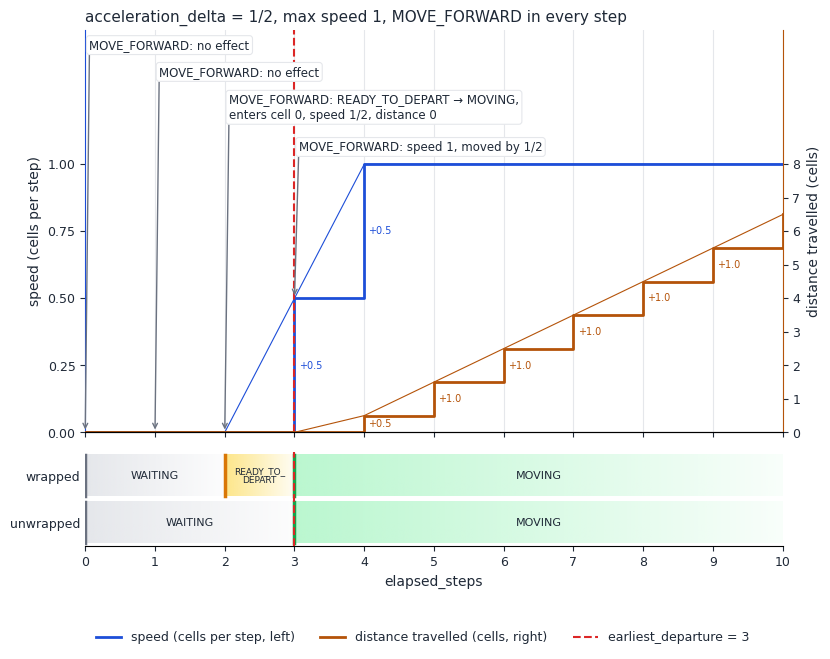

In [ ]:
plot_trajectory(Fraction(1, 2),
                speed=[0, 0, 0, Fraction(1, 2)] + [1] * 7,
                travelled=[0, 0, 0, 0] + [k - Fraction(1, 2) for k in range(1, 8)],
                states={"wrapped": [(0, 2, "WAITING"), (2, 3, "READY_TO_DEPART"), (3, 10, "MOVING")],
                        "unwrapped": [(0, 3, "WAITING"), (3, 10, "MOVING")]},
                labels=[(0, "MOVE_FORWARD: no effect", 0, 1.42, "speed"),
                        (1, "MOVE_FORWARD: no effect", 0, 1.32, "speed"),
                        (2, "MOVE_FORWARD: READY_TO_DEPART → MOVING,\nenters cell 0, speed 1/2, distance 0", 0, 1.16, "speed"),
                        (3, "MOVE_FORWARD: speed 1, moved by 1/2", 0.5, 1.04, "speed")])

The same table for the default `acceleration_delta=Fraction(1)`:

| `step()`  | `elapsed_steps` after `step()` | action in the step | state (wrapped, and `info['state']`) | cell | speed  | distance | distance travelled | `is_cell_entry` | `is_cell_exit()` |
|:----------|:-------------------------------|:-------------------|:-------------------------------------|:-----|:-------|:---------|:-------------------|:----------------|:-----------------|
| `reset()` | 0 (= `t-3`)                    | -                  | `WAITING`                            | -    | `None` | `None`   | `None`             | `False`         | `True`           |
| 0 → 1     | 1 (= `t-2`)                    | `MOVE_FORWARD`     | `WAITING`                            | -    | `None` | `None`   | `None`             | `False`         | `True`           |
| 1 → 2     | 2 (= `t-1`)                    | `MOVE_FORWARD`     | `READY_TO_DEPART`                    | -    | `None` | `None`   | `None`             | `False`         | `True`           |
| 2 → 3     | 3 (= `t`)                      | `MOVE_FORWARD`     | `MOVING`                             | 0    | 1      | 0        | 0                  | `True`          | `True`           |
| 3 → 4     | 4 (= `t+1`)                    | `MOVE_FORWARD`     | `MOVING`                             | 1    | 1      | 0        | 1                  | `True`          | `True`           |
| 4 → 5     | 5 (= `t+2`)                    | `MOVE_FORWARD`     | `MOVING`                             | 2    | 1      | 0        | 2                  | `True`          | `True`           |

The plot for this trajectory, again for `t = 3`: the agent has speed 1 from `elapsed_steps = 3` on, so the distance travelled goes up by a
whole cell at every step from `elapsed_steps = 4` on.

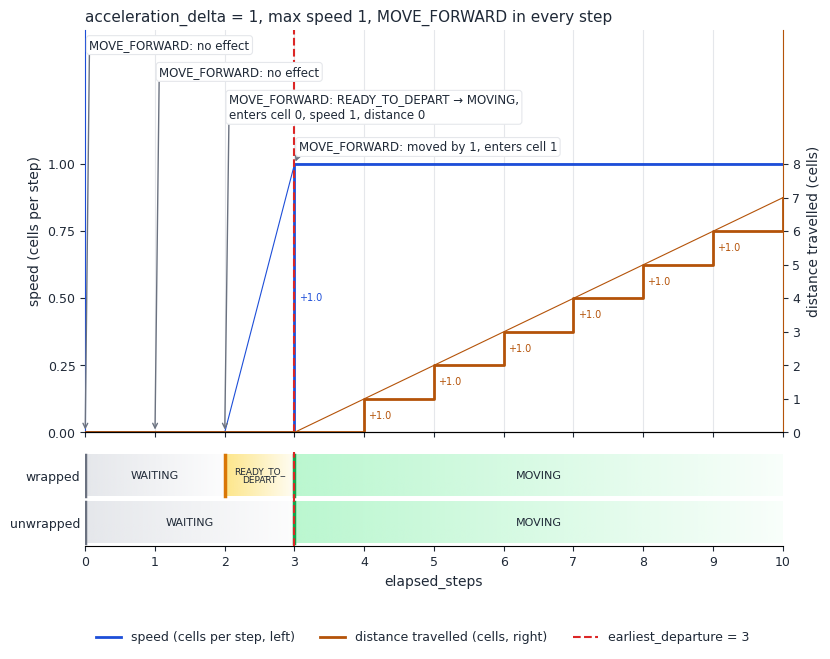

In [ ]:
plot_trajectory(Fraction(1),
                speed=[0, 0, 0] + [1] * 8,
                travelled=[0, 0, 0, 0] + list(range(1, 8)),
                states={"wrapped": [(0, 2, "WAITING"), (2, 3, "READY_TO_DEPART"), (3, 10, "MOVING")],
                        "unwrapped": [(0, 3, "WAITING"), (3, 10, "MOVING")]},
                labels=[(0, "MOVE_FORWARD: no effect", 0, 1.42, "speed"),
                        (1, "MOVE_FORWARD: no effect", 0, 1.32, "speed"),
                        (2, "MOVE_FORWARD: READY_TO_DEPART → MOVING,\nenters cell 0, speed 1, distance 0", 0, 1.16, "speed"),
                        (3, "MOVE_FORWARD: moved by 1, enters cell 1", 1, 1.04, "speed")])

With `acceleration_delta=1/2`, the agent reaches the next cell at `t+2` instead of `t+1`. From then on it also moves one cell per step, but half a cell
further along each cell. `is_cell_exit()` after a step announces that the agent crosses into the next cell in the following step, which is when a new
action is required (see [Actions](actions)).

## Creating a speed counter

```python
from fractions import Fraction
from flatland.envs.step_utils.speed_counter import SpeedCounter

speed_counter = SpeedCounter(max_speed=Fraction(1, 4))
```

Since `flatland 5.0.0`, the first parameter is `max_speed` and the optional second one the initial `speed`; up to `flatland 4.3.0`, it was
`SpeedCounter(speed, max_speed=None)`. Pass `max_speed=` as keyword to be explicit. `is_cell_exit()` no longer takes the speed as argument, and the
counter is no longer stepped by itself (`step()` is replaced by `set(speed, distance)` with values computed by the formulas above).

```{note}
`RailEnv`'s `acceleration_delta` and `braking_delta` default to the floats `1.0` and `-1.0` (`AbstractRailEnv`'s to `Fraction(1)` and
`-Fraction(1)`); the defaults work, as the speed is then always capped at the max speed or 0. Pass `Fraction`s for other values, e.g.
`acceleration_delta=Fraction(1, 2)`: a float such as `0.5` currently fails an assertion as soon as an agent whose max speed is above it enters the
map or accelerates.
```